# MySteth 2.0 — RQ2 (part b): does self-supervised pretraining give better-calibrated models, not just more accurate ones?

**RQ2 (methods document).** *How does self-supervised representation learning affect uncertainty quality and calibration in paediatric murmur detection?* Train SSL-pretrained and from-scratch encoders with identical heads, apply the identical UQ pipeline (RQ4) to all of them, and compare **accuracy/F1, ECE and reliability diagrams**. Part a built the encoders; this notebook compares them.

### The five MySteth 2.0 components and their role in this notebook

| # | Component | Role here |
|---|---|---|
| ① | **SQA** | **Off.** Every recording is used. RQ2 asks about the representation itself; the quality gate is tested in RQ1 and RQ6. |
| ② | **SSL** | **The thing being tested:** five encoder arms (below). |
| ③ | **Multi-task heads** | **On.** Every arm is trained for murmur (Present / Absent) and outcome (Normal / Abnormal), each task separately here. Joint (shared-encoder) training is RQ3. |
| ④ | **UQ** | **On, identical for every arm:** temperature scaling, MC-Dropout (40 passes) and a 3-seed deep ensemble (RQ4's definitions). |
| ⑤ | **XAI** | **Off** (RQ5). |

### The five arms (same network, data, folds, heads, training budget and UQ; only the encoder differs)

| Arm | Encoder starts from | Encoder trained? | Question it answers |
|---|---|---|---|
| **Scratch** | random weights | yes | What do labels alone achieve? |
| **CirCor-SSL, frozen** | BYOL-A on CirCor (fold's non-test recordings) | no | Are in-domain SSL features good as they are? |
| **CirCor-SSL, fine-tuned** | same | yes | Does in-domain pretraining help when adapted? |
| **Domain-SSL, frozen** | BYOL-A on CirCor + PhysioNet 2016 + PASCAL | no | Do adult and external recordings give better features? |
| **Domain-SSL, fine-tuned** | same | yes | ... and after adaptation? |

Each comparison isolates one factor:
- **fine-tuned SSL vs scratch:** the effect of pretraining, with every layer trained in both;
- **Domain vs CirCor:** the effect of the extra (domain-shifted) data, with the training budget matched;
- **fine-tuned vs frozen:** whether the features need adapting.

### What changed from the first RQ2 run, and why

| | first run | this run |
|---|---|---|
| SSL encoder | one encoder pretrained on **all** CirCor recordings, test recordings included | **one encoder per fold**, pretrained without that fold's test recordings (part a) |
| Pretraining corpus | CirCor only (the methods document's external corpora had been dropped) | CirCor-SSL **and** Domain-SSL (CirCor + PhysioNet 2016 + PASCAL), as the methods document specifies |
| Frozen-arm training budget | 30 epochs (the frozen heads were still improving at the cap) | **60 epochs, stop after 15 without improvement, for every arm** |
| Scratch arm | trained | **re-used unchanged** (same folds, code and budget) if `reuse_scratch_from` is set |

Unchanged: whole-recording windows (5 s, hop 2.5 s); plain unweighted loss with thresholds chosen on validation patients (murmur: maximise weighted accuracy; outcome: minimise c_outcome); 75 / 10 / 15 train / val / cal; patient-group bootstrap CIs.

### Fixed in advance: the system model and its starting point
> MySteth 2.0 (RQ3–RQ6) is the methods document's RQ3 model: **one shared encoder fine-tuned jointly on murmur and outcome**. It starts from the **Domain-SSL** encoder (the corpus the methods document specifies), **unless** CirCor-SSL fine-tuned is clearly better on murmur weighted accuracy (3-seed temperature-scaled ensemble; paired 95 % bootstrap CI of the difference entirely above 0). Section 9 applies this and saves `rq2_system_choice.json`.

*Note for the paper:* the first RQ2 run used a different rule (frozen vs per-task fine-tuned). It was replaced by the methods document's original RQ3 design before this run, and the report states this.

### Kaggle setup
GPU on. Attach (1) CirCor v2, (2) the **RQ2a output** (`rq2a_outputs`: folds file + six encoders), and optionally (3) the **first RQ2 output** (`rq2_outputs`) to reuse its scratch arm. Outputs go to `/kaggle/working/rq2_outputs`. Training is saved unit by unit; to continue an interrupted run, attach its output and set `resume_from`.

In [1]:
import os, math, random, json, time, glob, shutil, warnings
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import torchaudio.transforms as T
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print("Device:", device)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
NAVY, TEAL, ORANGE, RED, GRAY = "#1F3864", "#1F8A70", "#E67E22", "#C0392B", "#6B7280"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


@dataclass
class Config:
    # ---- EDIT THESE PATHS to match your Kaggle inputs ----
    circor_root: str = "/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2"
    rq2a_dir: str = "/kaggle/input/notebooks/tusharrbb/rq2-part-1-again/rq2a_outputs"          # rq2_folds.csv + encoders/
    reuse_scratch_from: str = "/kaggle/input/notebooks/tusharrbb/rq2-redone/rq2_outputs"   # first RQ2 run ("" to retrain scratch)
    output_dir: str = "/kaggle/working/rq2_outputs"
    resume_from: str = ""            # an interrupted run of THIS notebook

    sample_rate: int = 4000
    n_fft: int = 256
    hop_length: int = 32
    n_mels: int = 64
    fmin: float = 20.0
    fmax: float = 800.0
    window_sec: float = 5.0
    hop_sec: float = 2.5

    embed_dim: int = 512
    dropout_p: float = 0.5

    batch_size: int = 64
    head_lr: float = 1e-3
    finetune_encoder_lr: float = 1e-4
    scratch_lr: float = 1e-3
    weight_decay: float = 1e-5
    epochs: int = 60                 # same for every arm
    patience: int = 15

    n_folds: int = 3
    seeds: tuple = (42, 123, 7)
    mc_passes: int = 40
    n_boot: int = 1000

cfg = Config()
cfg.data_dir = os.path.join(cfg.circor_root, "training_data", "training_data")
OUT = Path(cfg.output_dir); OUT.mkdir(parents=True, exist_ok=True)
UNIT_DIR = OUT / "units"; UNIT_DIR.mkdir(exist_ok=True)
MODEL_DIR = OUT / "models"; MODEL_DIR.mkdir(exist_ok=True)
EMB_DIR = OUT / "frozen_embeddings"; EMB_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT / "figures"; FIG_DIR.mkdir(exist_ok=True)
ENC_DIR = Path(cfg.rq2a_dir) / "encoders"

ARMS = ["scratch", "circor_frozen", "circor_finetune", "domain_frozen", "domain_finetune"]
ARM_NAME = {"scratch": "Scratch", "circor_frozen": "CirCor-SSL frozen", "circor_finetune": "CirCor-SSL fine-tuned",
            "domain_frozen": "Domain-SSL frozen", "domain_finetune": "Domain-SSL fine-tuned"}
CORPUS = {"circor_frozen": "circor", "circor_finetune": "circor", "domain_frozen": "domain", "domain_finetune": "domain"}
FROZEN_ARMS = {"circor_frozen", "domain_frozen"}
ARM_COLOR = {"scratch": ORANGE, "circor_frozen": TEAL, "circor_finetune": TEAL, "domain_frozen": NAVY, "domain_finetune": NAVY}
ARM_LS = {a: ("--" if a in FROZEN_ARMS else "-") for a in ARMS}
TASKS = ["murmur", "outcome"]
RUN_ARMS = ARMS                  # to split training across sessions, e.g. RUN_ARMS = ["circor_frozen", "domain_frozen"]
assert all((ENC_DIR / f"byola_{c}_f{f}.pt").exists() for c in ["circor", "domain"] for f in range(cfg.n_folds)), "RQ2a encoders not found"
print(cfg)

Device: cuda
Config(circor_root='/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2', rq2a_dir='/kaggle/input/notebooks/tusharrbb/rq2-part-1-again/rq2a_outputs', reuse_scratch_from='/kaggle/input/notebooks/tusharrbb/rq2-redone/rq2_outputs', output_dir='/kaggle/working/rq2_outputs', resume_from='', sample_rate=4000, n_fft=256, hop_length=32, n_mels=64, fmin=20.0, fmax=800.0, window_sec=5.0, hop_sec=2.5, embed_dim=512, dropout_p=0.5, batch_size=64, head_lr=0.001, finetune_encoder_lr=0.0001, scratch_lr=0.001, weight_decay=1e-05, epochs=60, patience=15, n_folds=3, seeds=(42, 123, 7), mc_passes=40, n_boot=1000)


## 1. Recordings, labels and the shared folds file (from part a)

*Components: none yet (bookkeeping).*

The folds file from part a is loaded as is. It holds the patient groups (repeat-visit children linked via `Additional ID`), the 3 folds, and the `train` / `val` / `cal` / `test` role of every recording in every fold. Murmur labels are `Present = 1`, `Absent = 0`, and **`Unknown = -1`** (never trained on, but predicted). Outcome is `Abnormal = 1`, `Normal = 0`.

If the first RQ2 run is attached, its folds file is checked to be **identical**, which is the condition for reusing its scratch arm.

In [2]:
man = pd.read_csv(Path(cfg.rq2a_dir) / "rq2_folds.csv")
man["wav_path"] = [os.path.join(cfg.data_dir, w + ".wav") for w in man.wid]
assert all(os.path.exists(p) for p in man.wav_path)
N_REC = len(man)
man[[c for c in man.columns if c != "wav_path"]].to_csv(OUT / "rq2_folds.csv", index=False)

REUSE_SCRATCH = False
if cfg.reuse_scratch_from and (Path(cfg.reuse_scratch_from) / "rq2_folds.csv").exists():
    old = pd.read_csv(Path(cfg.reuse_scratch_from) / "rq2_folds.csv")
    REUSE_SCRATCH = old.drop(columns=[c for c in old.columns if c not in man.columns]).equals(
        man[[c for c in old.columns if c in man.columns]])
    print("first-run folds identical:", REUSE_SCRATCH)

print(f"recordings {N_REC} | patients {man.patient_id.nunique()} | groups {man.group.nunique()}")
pat0 = man.drop_duplicates("patient_id")
print(pd.crosstab(pat0.murmur, pat0.outcome, margins=True))

first-run folds identical: True
recordings 3163 | patients 942 | groups 872
outcome  Abnormal  Normal  All
murmur                        
Absent        263     432  695
Present       150      29  179
Unknown        43      25   68
All           456     486  942


## 2. Audio in memory, whole-recording windows, spectrograms and augmentation

*Components: none yet (signal preparation). Identical to the first RQ2 run.*

- All recordings are loaded once into memory at 4 kHz.
- **Windows:** 5 s every 2.5 s, plus a final window ending at the recording's end; short recordings give one zero-padded window. A recording's probability is the average of its windows' probabilities.
- **Training crops:** one random 5 s crop per recording per epoch, with the same PCG augmentation as BYOL-A: gain, noise, soft-clip, circular shift, time and frequency masking.
- The window table is saved as `rq2_windows.csv`.

In [3]:
def load_audio(path):
    wav, sr = torchaudio.load(path)
    wav = wav.mean(0) if wav.shape[0] > 1 else wav[0]
    if sr != cfg.sample_rate:
        wav = torchaudio.functional.resample(wav, sr, cfg.sample_rate)
    return wav.numpy().astype(np.float32)

AUDIO = [load_audio(p) for p in tqdm(man.wav_path, desc="loading audio")]
WIN = int(cfg.window_sec * cfg.sample_rate)
HOP = int(cfg.hop_sec * cfg.sample_rate)

def window_starts(L):
    if L <= WIN:
        return [0]
    s = list(range(0, L - WIN + 1, HOP))
    if s[-1] + WIN < L:
        s.append(L - WIN)
    return s

win_rec, win_start = [], []
for i, a in enumerate(AUDIO):
    for s in window_starts(len(a)):
        win_rec.append(i); win_start.append(s)
win_rec = np.array(win_rec); win_start = np.array(win_start)
N_WIN = len(win_rec)
win_counts = np.bincount(win_rec, minlength=N_REC)
win_first = np.r_[0, np.cumsum(win_counts)[:-1]]
REC_WINS = [np.arange(win_first[i], win_first[i] + win_counts[i]) for i in range(N_REC)]
def windows_of(rec_idx):
    return np.concatenate([REC_WINS[i] for i in rec_idx])

dur = np.array([len(a) for a in AUDIO]) / cfg.sample_rate
print(f"duration s: median {np.median(dur):.1f}, min {dur.min():.1f}, max {dur.max():.1f} | windows {N_WIN}")
pd.DataFrame({"window": np.arange(N_WIN), "wid": man.wid.values[win_rec], "rec_index": win_rec,
              "start_sample": win_start, "start_s": win_start / cfg.sample_rate}).to_csv(OUT / "rq2_windows.csv", index=False)

def crop(i, s):
    a = AUDIO[i][s:s + WIN]
    return a if len(a) == WIN else np.pad(a, (0, WIN - len(a)))

def random_crop(i):
    L = len(AUDIO[i])
    return crop(i, random.randint(0, L - WIN) if L > WIN else 0)

mel_tf = T.MelSpectrogram(sample_rate=cfg.sample_rate, n_fft=cfg.n_fft, hop_length=cfg.hop_length,
                          n_mels=cfg.n_mels, f_min=cfg.fmin, f_max=cfg.fmax, power=2.0).to(device)
db_tf = T.AmplitudeToDB(stype="power").to(device)
time_mask = T.TimeMasking(time_mask_param=15, iid_masks=True)
freq_mask = T.FrequencyMasking(freq_mask_param=8, iid_masks=True)

def log_mel(x):
    return db_tf(mel_tf(x)).unsqueeze(1)

def augment_wave(x):
    B = x.shape[0]
    U = lambda lo, hi: torch.empty(B, device=x.device).uniform_(lo, hi)
    on = lambda p: torch.rand(B, device=x.device) < p
    gain = torch.where(on(0.8), 10 ** (U(-6, 6) / 20), torch.ones(B, device=x.device))
    x = x * gain[:, None]
    p_sig = x.pow(2).mean(1).clamp(min=1e-8)
    noise = torch.randn_like(x) * (p_sig / 10 ** (U(10, 30) / 10)).sqrt()[:, None]
    x = torch.where(on(0.5)[:, None], x + noise, x)
    drive = U(1.2, 2.0)[:, None]
    x = torch.where(on(0.3)[:, None], torch.tanh(x * drive) / torch.tanh(drive), x)
    shift = torch.randint(0, WIN, (B,), device=x.device)
    idx = (torch.arange(WIN, device=x.device)[None, :] - shift[:, None]) % WIN
    x = torch.where(on(0.5)[:, None], torch.gather(x, 1, idx), x)
    return x

def augmented_batch(rec_idx):
    x = torch.from_numpy(np.stack([random_crop(i) for i in rec_idx])).to(device)
    return freq_mask(time_mask(log_mel(augment_wave(x))))

def window_batch(widx):
    x = torch.from_numpy(np.stack([crop(win_rec[j], win_start[j]) for j in widx])).to(device)
    return log_mel(x)

loading audio:   0%|          | 0/3163 [00:00<?, ?it/s]

duration s: median 21.5, min 5.2, max 64.5 | windows 27335


## 3. The network: one encoder, one small head

*Components: ② SSL (the encoder) and ③ the task head.*

Every arm uses the same `SmallResNetEncoder` (512-d) followed by Dropout 0.5 → Linear (2 outputs). The head's dropout is also what MC-Dropout uses (④). Each SSL arm loads **its fold's** encoder from part a, so the encoder for fold *f* has never seen fold *f*'s test recordings.

| Arm | encoder weights | encoder trainable | learning rates (Adam, weight decay 1e-5) |
|---|---|---|---|
| Scratch | random (set by the seed) | yes | 1e-3 everywhere |
| CirCor-SSL / Domain-SSL frozen | `byola_<corpus>_f<fold>.pt` | no (BatchNorm in inference mode) | head 1e-3 |
| CirCor-SSL / Domain-SSL fine-tuned | `byola_<corpus>_f<fold>.pt` | yes | encoder 1e-4, head 1e-3 |

In [4]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        return self.relu(out + identity)


class SmallResNetEncoder(nn.Module):
    def __init__(self, embed_dim=512):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, 32, 7, stride=2, padding=3, bias=False), nn.BatchNorm2d(32),
                                  nn.ReLU(inplace=True), nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = nn.Sequential(ResBlock(32, 64), ResBlock(64, 64))
        self.layer2 = nn.Sequential(ResBlock(64, 128, stride=2), ResBlock(128, 128))
        self.layer3 = nn.Sequential(ResBlock(128, 256, stride=2), ResBlock(256, 256))
        self.layer4 = nn.Sequential(ResBlock(256, embed_dim, stride=2), ResBlock(embed_dim, embed_dim))
        self.pool = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return self.pool(x).flatten(1)


class LinearDropoutHead(nn.Module):
    def __init__(self, embed_dim, n_classes, dropout_p=cfg.dropout_p):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout_p)
        self.fc = nn.Linear(embed_dim, n_classes)

    def forward(self, x):
        return self.fc(self.dropout(x))


class Net(nn.Module):
    def __init__(self, encoder, frozen):
        super().__init__()
        self.encoder, self.frozen = encoder, frozen
        self.head = LinearDropoutHead(cfg.embed_dim, 2)
        if frozen:
            for p in self.encoder.parameters():
                p.requires_grad = False

    def embed(self, spec):
        if self.frozen:
            with torch.no_grad():
                return self.encoder(spec)
        return self.encoder(spec)

    def forward(self, spec):
        return self.head(self.embed(spec))

    def train_mode(self):
        self.train()
        if self.frozen:
            self.encoder.eval()


def encoder_path(corpus, fold):
    return ENC_DIR / f"byola_{corpus}_f{fold}.pt"

def make_net(arm, fold):
    enc = SmallResNetEncoder(cfg.embed_dim)
    if arm != "scratch":
        enc.load_state_dict(torch.load(encoder_path(CORPUS[arm], fold), map_location="cpu"))
    return Net(enc, frozen=(arm in FROZEN_ARMS)).to(device)

def make_optimizer(arm, net):
    wd = cfg.weight_decay
    if arm in FROZEN_ARMS:
        return torch.optim.Adam(net.head.parameters(), lr=cfg.head_lr, weight_decay=wd)
    if arm == "scratch":
        return torch.optim.Adam(net.parameters(), lr=cfg.scratch_lr, weight_decay=wd)
    return torch.optim.Adam([{"params": net.encoder.parameters(), "lr": cfg.finetune_encoder_lr},
                             {"params": net.head.parameters(), "lr": cfg.head_lr}], weight_decay=wd)

## 4. Training recipe (identical across arms)

*Components: ② SSL (the arm) and ③ the head for one task.*

- **Loss:** plain cross-entropy with no class weights, so the probabilities stay honest. The decision threshold is chosen later on validation patients (section 7).
- **Murmur** trains on Present/Absent recordings only. **Outcome** trains on all recordings.
- **Inputs:** a fresh augmented crop of every recording each epoch, except the **frozen outcome heads**, which train on the frozen encoder's embeddings of every window without augmentation (RQ3 showed augmentation does not help outcome on a frozen encoder).
- **Budget, the same for every arm:** up to **60 epochs**, keeping the epoch with the lowest validation log-loss (validation recordings scored on all their windows), and stopping after **15 epochs** without improvement.

In [5]:
LABEL = {"murmur": man.y_murmur.values, "outcome": man.y_outcome.values}

def rows(task, fold, role):
    keep = man[f"role_f{fold}"].values == role
    if task == "murmur":
        keep &= LABEL["murmur"] >= 0
    return np.where(keep)[0]

_frozen_cache = {}
def frozen_embeddings(corpus, fold):
    # frozen BYOL-A embedding of every window, for one corpus x fold encoder (computed once, saved as float16)
    key = (corpus, fold)
    if key not in _frozen_cache:
        path = EMB_DIR / f"emb_{corpus}_f{fold}.npy"
        if path.exists():
            E = torch.from_numpy(np.load(path).astype(np.float32))
        else:
            enc = SmallResNetEncoder(cfg.embed_dim)
            enc.load_state_dict(torch.load(encoder_path(corpus, fold), map_location="cpu"))
            enc = enc.to(device).eval()
            with torch.no_grad():
                E = torch.cat([enc(window_batch(np.arange(k, min(k + 256, N_WIN)))).float().cpu()
                               for k in tqdm(range(0, N_WIN, 256), desc=f"frozen embeddings {corpus} f{fold}", leave=False)])
            np.save(path, E.numpy().astype(np.float16))
            del enc
        _frozen_cache.clear()                       # keep one encoder's embeddings in memory at a time
        _frozen_cache[key] = E
    return _frozen_cache[key]

@torch.no_grad()
def window_embeddings(net, arm, fold, widx, bs=256):
    if arm in FROZEN_ARMS:
        return frozen_embeddings(CORPUS[arm], fold)[widx]
    net.eval()
    return torch.cat([net.encoder(window_batch(widx[k:k + bs])).float().cpu() for k in range(0, len(widx), bs)])

@torch.no_grad()
def head_z(net, emb, bs=4096):
    out = []
    for k in range(0, len(emb), bs):
        l = net.head(emb[k:k + bs].to(device))
        out.append((l[:, 1] - l[:, 0]).float().cpu())
    return torch.cat(out).numpy()

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def val_logloss(net, arm, fold, va, y_va):
    widx = windows_of(va)
    owner = np.repeat(np.arange(len(va)), win_counts[va])
    net.eval()
    z = head_z(net, window_embeddings(net, arm, fold, widx))
    p = np.clip(np.bincount(owner, weights=sigmoid(z)) / win_counts[va], 1e-6, 1 - 1e-6)
    return float(-np.mean(y_va * np.log(p) + (1 - y_va) * np.log(1 - p)))

def train_unit(arm, task, fold, seed):
    set_seed(seed * 10 + fold)
    y = LABEL[task]
    tr, va = rows(task, fold, "train"), rows(task, fold, "val")
    net = make_net(arm, fold)
    opt = make_optimizer(arm, net)
    crit = nn.CrossEntropyLoss()
    cached = (arm in FROZEN_ARMS and task == "outcome")
    if cached:
        tr_w = windows_of(tr)
        X, Yw = frozen_embeddings(CORPUS[arm], fold)[tr_w], torch.tensor(y[win_rec[tr_w]], dtype=torch.long)
    best_loss, best_ep, best_state, curve = np.inf, -1, None, []
    for ep in range(cfg.epochs):
        net.train_mode()
        if cached:
            perm = torch.randperm(len(X))
            for k in range(0, len(X), cfg.batch_size):
                b = perm[k:k + cfg.batch_size]
                loss = crit(net.head(X[b].to(device)), Yw[b].to(device))
                opt.zero_grad(); loss.backward(); opt.step()
        else:
            order = np.random.permutation(tr)
            for k in range(0, len(order), cfg.batch_size):
                b = order[k:k + cfg.batch_size]
                if len(b) < 2:
                    continue
                loss = crit(net(augmented_batch(b)), torch.tensor(y[b], dtype=torch.long, device=device))
                opt.zero_grad(); loss.backward(); opt.step()
        vl = val_logloss(net, arm, fold, va, y[va])
        curve.append(vl)
        if vl < best_loss:
            best_loss, best_ep = vl, ep
            best_state = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
        elif ep - best_ep >= cfg.patience:
            break
    net.load_state_dict(best_state)
    net.eval()
    return net, np.array(curve), best_ep

## 5. Predictions saved by every training unit

*Components: ④ UQ (raw ingredients for all three methods).*

Each unit (arm × task × fold × seed) predicts **every window of every recording**. Two things go into `units/<arm>_<task>_f<fold>_s<seed>.npz`:
- `z_det`: the deterministic logit difference per window;
- `z_mc` (seed-42 units only): 40 MC-Dropout passes per window, with dropout on in the head only.

Logits, not probabilities, are saved, so temperatures, thresholds and aggregation can be recomputed on CPU at any time. Weights go to `models/`: the head only for frozen arms, the full network otherwise.

In [6]:
@torch.no_grad()
def predict_unit(net, arm, fold, with_mc, seed):
    emb = window_embeddings(net, arm, fold, np.arange(N_WIN))
    net.eval()
    z_det = head_z(net, emb).astype(np.float32)
    z_mc = np.zeros((0, cfg.mc_passes), dtype=np.float16)
    if with_mc:
        set_seed(seed + 999)
        net.head.train()
        z_mc = np.stack([head_z(net, emb) for _ in range(cfg.mc_passes)], axis=1).astype(np.float16)
        net.head.eval()
    return z_det, z_mc

## 6. Run all training units (resumable)

*Components: ② SSL × ③ both tasks × ④ UQ ingredients.*

That's 5 arms × 2 tasks × 3 folds × 3 seeds = **90 units**:
- **Scratch units** are copied from the first RQ2 run when its folds file is identical (checked in section 1). Its code, seeds and 60/15 budget are unchanged, so these are exactly the units this notebook would train.
- A unit whose `.npz` already exists is skipped. For an interrupted run, set `resume_from`.
- Frozen embeddings are computed once per corpus × fold and saved in `frozen_embeddings/`.

In [7]:
def copy_units(src, arms):
    n = 0
    for sub in ["units", "models"]:
        for fpath in (Path(src) / sub).glob("*"):
            if any(fpath.name.startswith(a + "_") for a in arms):
                if not (OUT / sub / fpath.name).exists():
                    shutil.copy(fpath, OUT / sub / fpath.name); n += 1
    return n

log_path = OUT / "rq2_training_log.csv"
log = pd.read_csv(log_path).to_dict("records") if log_path.exists() else []
if cfg.resume_from:
    print("copied from resume_from:", copy_units(cfg.resume_from, ARMS))
    for sub in ["frozen_embeddings"]:
        for fpath in (Path(cfg.resume_from) / sub).glob("*"):
            if not (OUT / sub / fpath.name).exists():
                shutil.copy(fpath, OUT / sub / fpath.name)
    if (Path(cfg.resume_from) / "rq2_training_log.csv").exists() and not log:
        log = pd.read_csv(Path(cfg.resume_from) / "rq2_training_log.csv").to_dict("records")
if REUSE_SCRATCH:
    print("scratch files copied from the first RQ2 run:", copy_units(cfg.reuse_scratch_from, ["scratch"]))
    old_log = pd.read_csv(Path(cfg.reuse_scratch_from) / "rq2_training_log.csv")
    have = {r["unit"] for r in log}
    log += [r for r in old_log[old_log.arm == "scratch"].to_dict("records") if r["unit"] not in have]
pd.DataFrame(log).to_csv(log_path, index=False)

units = [(a, t, f, s) for a in RUN_ARMS for t in TASKS for f in range(cfg.n_folds) for s in cfg.seeds]
for arm, task, fold, seed in tqdm(units, desc="training units"):
    name = f"{arm}_{task}_f{fold}_s{seed}"
    if (UNIT_DIR / f"{name}.npz").exists():
        continue
    t0 = time.time()
    net, curve, best_ep = train_unit(arm, task, fold, seed)
    z_det, z_mc = predict_unit(net, arm, fold, with_mc=(seed == cfg.seeds[0]), seed=seed)
    np.savez_compressed(UNIT_DIR / f"{name}.npz", z_det=z_det, z_mc=z_mc, curve=curve, best_epoch=best_ep)
    state = net.head.state_dict() if arm in FROZEN_ARMS else net.state_dict()
    torch.save({k: v.cpu() for k, v in state.items()}, MODEL_DIR / f"{name}.pt")
    log.append({"unit": name, "arm": arm, "task": task, "fold": fold, "seed": seed, "best_epoch": best_ep,
                "epochs_run": len(curve), "best_val_logloss": float(curve[best_ep]), "minutes": (time.time() - t0) / 60})
    pd.DataFrame(log).to_csv(log_path, index=False)
    print(f"{name}: best epoch {best_ep} / {len(curve)}, val log-loss {curve[best_ep]:.4f}, {(time.time() - t0) / 60:.1f} min")
    del net; torch.cuda.empty_cache()

missing = [f"{a}_{t}_f{f}_s{s}" for a in ARMS for t in TASKS for f in range(cfg.n_folds) for s in cfg.seeds
           if not (UNIT_DIR / f"{a}_{t}_f{f}_s{s}.npz").exists()]
print("units missing:", len(missing), missing[:6])
assert not missing, "finish all units before running the analysis below"

scratch files copied from the first RQ2 run: 36


training units:   0%|          | 0/90 [00:00<?, ?it/s]

frozen embeddings circor f0:   0%|          | 0/107 [00:00<?, ?it/s]

circor_frozen_murmur_f0_s42: best epoch 43 / 59, val log-loss 0.3265, 1.5 min
circor_frozen_murmur_f0_s123: best epoch 57 / 60, val log-loss 0.3249, 1.1 min
circor_frozen_murmur_f0_s7: best epoch 47 / 60, val log-loss 0.3269, 1.2 min


frozen embeddings circor f1:   0%|          | 0/107 [00:00<?, ?it/s]

circor_frozen_murmur_f1_s42: best epoch 19 / 35, val log-loss 0.2270, 1.2 min
circor_frozen_murmur_f1_s123: best epoch 46 / 60, val log-loss 0.2261, 1.2 min
circor_frozen_murmur_f1_s7: best epoch 19 / 35, val log-loss 0.2272, 0.7 min


... (4 outputs left out)

frozen embeddings domain f1:   0%|          | 0/107 [00:00<?, ?it/s]

domain_frozen_murmur_f1_s42: best epoch 47 / 60, val log-loss 0.2411, 1.8 min
domain_frozen_murmur_f1_s123: best epoch 44 / 60, val log-loss 0.2382, 1.3 min
domain_frozen_murmur_f1_s7: best epoch 32 / 48, val log-loss 0.2416, 1.0 min


frozen embeddings domain f2:   0%|          | 0/107 [00:00<?, ?it/s]

domain_frozen_murmur_f2_s42: best epoch 38 / 54, val log-loss 0.2136, 1.7 min
domain_frozen_murmur_f2_s123: best epoch 26 / 42, val log-loss 0.2170, 0.9 min
domain_frozen_murmur_f2_s7: best epoch 35 / 51, val log-loss 0.2137, 1.1 min
domain_frozen_outcome_f0_s42: best epoch 28 / 44, val log-loss 0.6525, 0.2 min
domain_frozen_outcome_f0_s123: best epoch 4 / 20, val log-loss 0.6571, 0.1 min
domain_frozen_outcome_f0_s7: best epoch 0 / 16, val log-loss 0.6568, 0.1 min
domain_frozen_outcome_f1_s42: best epoch 5 / 21, val log-loss 0.6221, 0.1 min
domain_frozen_outcome_f1_s123: best epoch 19 / 35, val log-loss 0.6149, 0.2 min
domain_frozen_outcome_f1_s7: best epoch 3 / 19, val log-loss 0.6206, 0.1 min
domain_frozen_outcome_f2_s42: best epoch 18 / 34, val log-loss 0.5535, 0.2 min
domain_frozen_outcome_f2_s123: best epoch 9 / 25, val log-loss 0.5528, 0.1 min
domain_frozen_outcome_f2_s7: best epoch 14 / 30, val log-loss 0.5486, 0.1 min
domain_finetune_murmur_f0_s42: best epoch 9 / 25, val log-lo

---
# Analysis (CPU only from here; reruns from the saved units)

## 7. Uncertainty methods, temperatures and decision thresholds

*Components: ④ UQ, applied identically to every arm; ③ patient-level decisions for both tasks.*

**Recording probability** = average of its windows' probabilities. **Patient probability**: murmur = the **highest** recording; outcome = the **mean** of the recordings.

| method | how |
|---|---|
| `single` | seed-42 model, raw |
| `temp` | seed-42 model, **temperature-scaled**: T fitted on the fold's **calibration** patients (recording-level log-loss) |
| `mc` | seed-42 model, mean of 40 **MC-Dropout** passes |
| `ens` | **deep ensemble**: mean of the 3 seeds' raw probabilities |
| `ens_temp` | mean of the 3 seeds' temperature-scaled probabilities. The system rule (section 9) uses this. |

**Thresholds:** chosen per fold and method on that fold's **validation** patients. Murmur: maximise weighted accuracy (Present 5, Absent 1). Outcome: minimise c_outcome. Ties go to the threshold closest to 0.5. Unknown-murmur patients never enter murmur temperatures, thresholds or metrics.

In [8]:
def rec_mean(v):
    return np.add.reduceat(v, win_first, axis=0) / (win_counts if v.ndim == 1 else win_counts[:, None])

def bin_entropy(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

def fit_temperature(z, rec_idx, y):
    def nll(logT):
        p = np.clip(rec_mean(sigmoid(z / np.exp(logT)))[rec_idx], 1e-6, 1 - 1e-6)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))

METHODS = ["single", "temp", "mc", "ens", "ens_temp"]
OOF, FOLDP, UNC, temp_rows = {}, {}, {}, []
for arm in ARMS:
    for task in TASKS:
        y = LABEL[task]
        oof = {m: np.full(N_REC, np.nan) for m in METHODS}
        unc = {k: np.full(N_REC, np.nan) for k in ["mc_entropy", "mc_mutual_info", "ens_std"]}
        for f in range(cfg.n_folds):
            cal, test = rows(task, f, "cal"), np.where(man.fold.values == f)[0]
            p_raw, p_T = [], []
            for s in cfg.seeds:
                d = np.load(UNIT_DIR / f"{arm}_{task}_f{f}_s{s}.npz")
                z = d["z_det"].astype(np.float64)
                Tm = fit_temperature(z, cal, y[cal])
                temp_rows.append({"arm": arm, "task": task, "fold": f, "seed": s, "temperature": Tm})
                p_raw.append(rec_mean(sigmoid(z))); p_T.append(rec_mean(sigmoid(z / Tm)))
                if s == cfg.seeds[0]:
                    p_pass = rec_mean(sigmoid(d["z_mc"].astype(np.float64)))
            fp = {"single": p_raw[0], "temp": p_T[0], "mc": p_pass.mean(1),
                  "ens": np.mean(p_raw, 0), "ens_temp": np.mean(p_T, 0)}
            for m in METHODS:
                oof[m][test] = fp[m][test]
                FOLDP[(arm, task, m, f)] = fp[m]
            H = bin_entropy(p_pass.mean(1))
            unc["mc_entropy"][test] = H[test]
            unc["mc_mutual_info"][test] = (H - bin_entropy(p_pass).mean(1))[test]
            unc["ens_std"][test] = np.std(p_raw, 0)[test]
        for m in METHODS:
            OOF[(arm, task, m)] = oof[m]
        UNC[(arm, task)] = unc
temps = pd.DataFrame(temp_rows)
print("temperatures (T > 1: model was overconfident; T < 1: underconfident):")
print(temps.groupby(["task", "arm"]).temperature.agg(["mean", "min", "max"]).round(3))

temperatures (T > 1: model was overconfident; T < 1: underconfident):
                          mean    min    max
task    arm                                 
murmur  circor_finetune  1.388  0.804  2.321
        circor_frozen    0.843  0.780  0.922
        domain_finetune  1.373  0.769  2.283
        domain_frozen    0.906  0.790  1.068
        scratch          0.881  0.745  1.070
outcome circor_finetune  1.755  1.215  2.393
        circor_frozen    0.977  0.781  1.144
        domain_finetune  1.591  1.084  2.143
        domain_frozen    0.928  0.702  1.191
        scratch          1.454  0.853  2.928


In [9]:
PAT = man.drop_duplicates("patient_id")[["patient_id", "group", "fold", "murmur", "outcome", "y_murmur", "y_outcome"]
                                        + [f"role_f{f}" for f in range(cfg.n_folds)]].reset_index(drop=True)
rec_pat = man.patient_id.map(dict(zip(PAT.patient_id, PAT.index))).values
PLABEL = {"murmur": PAT.y_murmur.values, "outcome": PAT.y_outcome.values}

def to_patient(p_rec, task):
    s = pd.Series(p_rec).groupby(rec_pat)
    return (s.max() if task == "murmur" else s.mean()).reindex(range(len(PAT))).values

def weighted_accuracy(y, yhat):
    tp = ((yhat == 1) & (y == 1)).sum(); tn = ((yhat == 0) & (y == 0)).sum()
    return (5 * tp + tn) / (5 * (y == 1).sum() + (y == 0).sum())

def c_outcome(y, yhat):
    n = len(y); r = yhat.mean()
    tp = ((yhat == 1) & (y == 1)).sum(); fn = ((yhat == 0) & (y == 1)).sum()
    return (10 * n + (25 + 397 * r - 1718 * r ** 2 + 11296 * r ** 4) * n + 10000 * tp + 50000 * fn) / n

GRID = np.round(np.arange(0.01, 1.0, 0.01), 2)
def choose_threshold(y, p, task):
    if task == "murmur":
        score = np.array([weighted_accuracy(y, (p >= t).astype(int)) for t in GRID])
    else:
        score = -np.array([c_outcome(y, (p >= t).astype(int)) for t in GRID])
    best = np.flatnonzero(np.isclose(score, score.max()))
    return float(GRID[best[np.argmin(np.abs(GRID[best] - 0.5))]])

THR, thr_rows, PATP = {}, [], {}
for arm in ARMS:
    for task in TASKS:
        yp = PLABEL[task]
        for m in METHODS:
            PATP[(arm, task, m)] = to_patient(OOF[(arm, task, m)], task)
            for f in range(cfg.n_folds):
                v = np.where((PAT[f"role_f{f}"].values == "val") & (yp >= 0))[0]
                t = choose_threshold(yp[v], to_patient(FOLDP[(arm, task, m, f)], task)[v], task)
                THR[(arm, task, m, f)] = t
                thr_rows.append({"arm": arm, "task": task, "method": m, "fold": f, "threshold": t, "n_val_patients": len(v)})
thresholds = pd.DataFrame(thr_rows)
print(thresholds[thresholds.method == "ens_temp"].pivot_table(index=["task", "fold"], columns="arm", values="threshold").round(2))

arm           circor_finetune  circor_frozen  domain_finetune  domain_frozen  scratch
task    fold                                                                         
murmur  0                0.50           0.27             0.31           0.26     0.26
        1                0.45           0.24             0.38           0.13     0.35
        2                0.34           0.24             0.50           0.30     0.36
outcome 0                0.46           0.44             0.44           0.47     0.46
        1                0.39           0.34             0.42           0.35     0.42
        2                0.41           0.39             0.40           0.40     0.42


## 8. Results: accuracy and calibration, every arm × task × method

*Components: ② SSL (rows), ③ both tasks, ④ every UQ method.*

- **Discrimination, at patient level** (out-of-fold test patients): F1 (macro), Accuracy, Weighted accuracy, AUC, plus c_outcome for outcome. Murmur uses Present/Absent patients only; outcome uses all patients.
- **Calibration, at recording level** (where temperatures are fitted): ECE (10 equal-width bins of the predicted positive-class probability), Brier, log-loss, plus recording AUC.
- **95 % CIs:** 1,000 bootstrap resamples of patient groups. The same resamples are used for every arm, so the differences in section 9 are paired.

In [10]:
def ece_binary(y, p, n_bins=10):
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    e = 0.0
    for b in range(n_bins):
        m = bins == b
        if m.any():
            e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e

def patient_metrics(y, p, yhat, task):
    out = {"F1 (macro)": f1_score(y, yhat, average="macro"), "Accuracy": accuracy_score(y, yhat),
           "Weighted accuracy": weighted_accuracy(y, yhat),
           "AUC": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan}
    if task == "outcome":
        out["Cost (c_outcome)"] = c_outcome(y, yhat)
    return out

def recording_metrics(y, p):
    pc = np.clip(p, 1e-6, 1 - 1e-6)
    return {"AUC": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan, "ECE": ece_binary(y, p),
            "Brier": np.mean((p - y) ** 2), "Log-loss": -np.mean(y * np.log(pc) + (1 - y) * np.log(1 - pc))}

rng = np.random.default_rng(SEED)
G_ALL = np.array(sorted(man.group.unique()))
BOOT_GROUPS = [rng.choice(G_ALL, size=len(G_ALL), replace=True) for _ in range(cfg.n_boot)]
def boot_index_sets(unit_groups):
    pos = pd.Series(np.arange(len(unit_groups))).groupby(unit_groups).apply(np.array).to_dict()
    return [np.concatenate([pos[g] for g in bg if g in pos]) for bg in BOOT_GROUPS]

EVAL_PAT = {t: np.where(PLABEL[t] >= 0)[0] for t in TASKS}
EVAL_REC = {t: np.where(LABEL[t] >= 0)[0] for t in TASKS}
BI_PAT = {t: boot_index_sets(PAT.group.values[EVAL_PAT[t]]) for t in TASKS}
BI_REC = {t: boot_index_sets(man.group.values[EVAL_REC[t]]) for t in TASKS}

res_rows, BOOT = [], {}
for arm in tqdm(ARMS, desc="bootstrap"):
    for task in TASKS:
        for m in METHODS:
            ip = EVAL_PAT[task]; y = PLABEL[task][ip]; p = PATP[(arm, task, m)][ip]
            thr = np.array([THR[(arm, task, m, f)] for f in PAT.fold.values[ip]])
            yhat = (p >= thr).astype(int)
            point = patient_metrics(y, p, yhat, task)
            bs = [patient_metrics(y[b], p[b], yhat[b], task) for b in BI_PAT[task]]
            for k, v in point.items():
                arr = np.array([d[k] for d in bs]); BOOT[(arm, task, m, "patient", k)] = arr
                res_rows.append({"arm": arm, "task": task, "method": m, "level": "patient", "metric": k, "value": v,
                                 "ci_low": np.nanpercentile(arr, 2.5), "ci_high": np.nanpercentile(arr, 97.5)})
            ir = EVAL_REC[task]; y = LABEL[task][ir]; p = OOF[(arm, task, m)][ir]
            point = recording_metrics(y, p)
            bs = [recording_metrics(y[b], p[b]) for b in BI_REC[task]]
            for k, v in point.items():
                arr = np.array([d[k] for d in bs]); BOOT[(arm, task, m, "recording", k)] = arr
                res_rows.append({"arm": arm, "task": task, "method": m, "level": "recording", "metric": k, "value": v,
                                 "ci_low": np.nanpercentile(arr, 2.5), "ci_high": np.nanpercentile(arr, 97.5)})
results = pd.DataFrame(res_rows)
POINT = {(r.arm, r.task, r.method, r.level, r.metric): r.value for r in results.itertuples()}
results["arm_name"] = results.arm.map(ARM_NAME)
fmt = lambda r: f"{r.value:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]" if r.metric != "Cost (c_outcome)" else f"{r.value:,.0f} [{r.ci_low:,.0f}, {r.ci_high:,.0f}]"
results["value (95% CI)"] = results.apply(fmt, axis=1)
for task in TASKS:
    for level in ["patient", "recording"]:
        sub = results[(results.task == task) & (results.level == level)].copy()
        sub["arm_name"] = pd.Categorical(sub.arm_name, [ARM_NAME[a] for a in ARMS], ordered=True)
        print(f"\n=== {task.upper()} | {level} level ===")
        display(sub.pivot_table(index=["method", "arm_name"], columns="metric", values="value (95% CI)", aggfunc="first", observed=True)
                .reindex(METHODS, level=0))

bootstrap:   0%|          | 0/5 [00:00<?, ?it/s]


=== MURMUR | patient level ===


metric                                           AUC              Accuracy            F1 (macro)     Weighted accuracy
method   arm_name                                                                                                     
single   Scratch                0.927 [0.898, 0.955]  0.880 [0.853, 0.901]  0.834 [0.802, 0.862]  0.871 [0.838, 0.902]
         CirCor-SSL frozen      0.900 [0.864, 0.933]  0.888 [0.866, 0.909]  0.836 [0.804, 0.867]  0.845 [0.809, 0.880]
         CirCor-SSL fine-tuned  0.921 [0.887, 0.951]  0.918 [0.897, 0.936]  0.874 [0.842, 0.902]  0.867 [0.827, 0.901]
         Domain-SSL frozen      0.880 [0.842, 0.914]  0.826 [0.800, 0.853]  0.765 [0.730, 0.799]  0.801 [0.762, 0.836]
         Domain-SSL fine-tuned  0.927 [0.895, 0.953]  0.898 [0.878, 0.919]  0.851 [0.821, 0.881]  0.864 [0.830, 0.897]
temp     Scratch                0.926 [0.898, 0.954]  0.881 [0.856, 0.902]  0.835 [0.804, 0.864]  0.874 [0.842, 0.904]
         CirCor-SSL frozen      0.903 [0.868, 0.935]  0.888 [0.866, 0.909]  0.836 [0.804, 0.867]  0.848 [0.813, 0.883]
         CirCor-SSL fine-tuned  0.918 [0.886, 0.948]  0.919 [0.898, 0.937]  0.876 [0.844, 0.904]  0.867 [0.827, 0.902]
         Domain-SSL frozen      0.885 [0.848, 0.918]  0.795 [0.768, 0.822]  0.736 [0.700, 0.769]  0.789 [0.752, 0.824]
         Domain-SSL fine-tuned  0.929 [0.898, 0.955]  0.900 [0.879, 0.922]  0.854 [0.822, 0.883]  0.865 [0.830, 0.900]
mc       Scratch                0.927 [0.899, 0.955]  0.880 [0.853, 0.901]  0.834 [0.802, 0.862]  0.871 [0.838, 0.902]
         CirCor-SSL frozen      0.901 [0.867, 0.934]  0.895 [0.874, 0.916]  0.844 [0.813, 0.875]  0.849 [0.814, 0.885]
         CirCor-SSL fine-tuned  0.921 [0.887, 0.951]  0.918 [0.897, 0.936]  0.874 [0.842, 0.902]  0.867 [0.827, 0.901]
         Domain-SSL frozen      0.879 [0.841, 0.913]  0.856 [0.830, 0.880]  0.795 [0.760, 0.829]  0.813 [0.772, 0.849]
         Domain-SSL fine-tuned  0.927 [0.895, 0.953]  0.900 [0.878, 0.922]  0.853 [0.822, 0.884]  0.862 [0.827, 0.898]
ens      Scratch                0.927 [0.898, 0.954]  0.886 [0.864, 0.907]  0.837 [0.803, 0.867]  0.859 [0.825, 0.893]
         CirCor-SSL frozen      0.904 [0.869, 0.936]  0.886 [0.864, 0.909]  0.834 [0.803, 0.865]  0.849 [0.815, 0.885]
         CirCor-SSL fine-tuned  0.934 [0.905, 0.960]  0.914 [0.894, 0.934]  0.872 [0.841, 0.900]  0.877 [0.841, 0.909]
         Domain-SSL frozen      0.880 [0.844, 0.915]  0.852 [0.827, 0.877]  0.792 [0.757, 0.826]  0.813 [0.772, 0.849]
         Domain-SSL fine-tuned  0.934 [0.905, 0.961]  0.883 [0.862, 0.906]  0.837 [0.807, 0.867]  0.870 [0.837, 0.903]
ens_temp Scratch                0.928 [0.901, 0.955]  0.890 [0.868, 0.911]  0.842 [0.810, 0.872]  0.862 [0.827, 0.895]
         CirCor-SSL frozen      0.906 [0.871, 0.937]  0.886 [0.863, 0.909]  0.834 [0.803, 0.865]  0.849 [0.815, 0.885]
         CirCor-SSL fine-tuned  0.930 [0.901, 0.956]  0.916 [0.896, 0.935]  0.875 [0.845, 0.902]  0.879 [0.843, 0.910]
         Domain-SSL frozen      0.885 [0.849, 0.919]  0.796 [0.768, 0.824]  0.737 [0.702, 0.770]  0.790 [0.753, 0.825]
         Domain-SSL fine-tuned  0.931 [0.901, 0.958]  0.888 [0.866, 0.910]  0.841 [0.811, 0.871]  0.868 [0.832, 0.901]


=== MURMUR | recording level ===


metric                                           AUC                 Brier                   ECE              Log-loss
method   arm_name                                                                                                     
single   Scratch                0.892 [0.864, 0.917]  0.076 [0.064, 0.089]  0.020 [0.016, 0.033]  0.273 [0.236, 0.313]
         CirCor-SSL frozen      0.884 [0.851, 0.912]  0.085 [0.072, 0.100]  0.042 [0.031, 0.057]  0.295 [0.257, 0.338]
         CirCor-SSL fine-tuned  0.885 [0.852, 0.912]  0.075 [0.063, 0.090]  0.032 [0.023, 0.047]  0.300 [0.248, 0.358]
         Domain-SSL frozen      0.861 [0.826, 0.891]  0.089 [0.075, 0.104]  0.031 [0.025, 0.048]  0.309 [0.270, 0.352]
         Domain-SSL fine-tuned  0.883 [0.849, 0.912]  0.079 [0.066, 0.092]  0.040 [0.030, 0.054]  0.320 [0.263, 0.384]
temp     Scratch                0.893 [0.865, 0.918]  0.076 [0.063, 0.089]  0.019 [0.013, 0.038]  0.276 [0.233, 0.320]
         CirCor-SSL frozen      0.887 [0.856, 0.915]  0.085 [0.070, 0.101]  0.038 [0.027, 0.058]  0.293 [0.250, 0.341]
         CirCor-SSL fine-tuned  0.888 [0.857, 0.915]  0.076 [0.064, 0.090]  0.035 [0.026, 0.049]  0.284 [0.242, 0.332]
         Domain-SSL frozen      0.866 [0.833, 0.895]  0.088 [0.074, 0.104]  0.032 [0.022, 0.050]  0.306 [0.263, 0.353]
         Domain-SSL fine-tuned  0.890 [0.858, 0.917]  0.078 [0.066, 0.091]  0.035 [0.026, 0.049]  0.298 [0.252, 0.348]
mc       Scratch                0.893 [0.865, 0.918]  0.076 [0.064, 0.089]  0.021 [0.017, 0.035]  0.273 [0.236, 0.311]
         CirCor-SSL frozen      0.885 [0.853, 0.913]  0.086 [0.074, 0.100]  0.060 [0.045, 0.075]  0.302 [0.269, 0.339]
         CirCor-SSL fine-tuned  0.884 [0.852, 0.912]  0.076 [0.063, 0.090]  0.032 [0.023, 0.048]  0.296 [0.247, 0.352]
         Domain-SSL frozen      0.861 [0.827, 0.891]  0.090 [0.077, 0.105]  0.050 [0.038, 0.066]  0.314 [0.279, 0.352]
         Domain-SSL fine-tuned  0.883 [0.849, 0.912]  0.079 [0.066, 0.092]  0.041 [0.031, 0.055]  0.316 [0.261, 0.378]
ens      Scratch                0.901 [0.875, 0.927]  0.073 [0.061, 0.086]  0.023 [0.015, 0.037]  0.262 [0.226, 0.300]
         CirCor-SSL frozen      0.886 [0.854, 0.914]  0.084 [0.071, 0.099]  0.044 [0.031, 0.058]  0.293 [0.256, 0.335]
         CirCor-SSL fine-tuned  0.894 [0.864, 0.921]  0.073 [0.060, 0.086]  0.027 [0.019, 0.041]  0.282 [0.233, 0.335]
         Domain-SSL frozen      0.864 [0.830, 0.894]  0.089 [0.075, 0.104]  0.030 [0.024, 0.047]  0.307 [0.268, 0.351]
         Domain-SSL fine-tuned  0.900 [0.870, 0.926]  0.072 [0.059, 0.085]  0.026 [0.019, 0.040]  0.272 [0.225, 0.322]
ens_temp Scratch                0.905 [0.879, 0.929]  0.073 [0.060, 0.086]  0.020 [0.014, 0.037]  0.259 [0.220, 0.300]
         CirCor-SSL frozen      0.888 [0.858, 0.915]  0.084 [0.070, 0.100]  0.037 [0.025, 0.057]  0.291 [0.248, 0.339]
         CirCor-SSL fine-tuned  0.898 [0.869, 0.924]  0.074 [0.062, 0.087]  0.033 [0.024, 0.046]  0.270 [0.229, 0.314]
         Domain-SSL frozen      0.868 [0.836, 0.897]  0.088 [0.074, 0.104]  0.031 [0.022, 0.050]  0.304 [0.262, 0.351]
         Domain-SSL fine-tuned  0.903 [0.875, 0.927]  0.073 [0.060, 0.085]  0.026 [0.019, 0.039]  0.264 [0.225, 0.305]


=== OUTCOME | patient level ===


metric                                           AUC              Accuracy         Cost (c_outcome)            F1 (macro)     Weighted accuracy
method   arm_name                                                                                                                              
single   Scratch                0.637 [0.600, 0.672]  0.572 [0.540, 0.603]  11,080 [10,264, 11,958]  0.551 [0.518, 0.584]  0.733 [0.698, 0.764]
         CirCor-SSL frozen      0.656 [0.619, 0.690]  0.575 [0.545, 0.606]  11,362 [10,405, 12,332]  0.564 [0.533, 0.594]  0.698 [0.662, 0.732]
         CirCor-SSL fine-tuned  0.638 [0.602, 0.674]  0.552 [0.521, 0.585]  11,538 [10,620, 12,446]  0.532 [0.500, 0.564]  0.704 [0.670, 0.738]
         Domain-SSL frozen      0.662 [0.624, 0.700]  0.586 [0.554, 0.620]  11,450 [10,472, 12,511]  0.579 [0.547, 0.611]  0.685 [0.647, 0.721]
         Domain-SSL fine-tuned  0.642 [0.604, 0.677]  0.565 [0.533, 0.596]  11,626 [10,688, 12,626]  0.554 [0.522, 0.586]  0.683 [0.646, 0.716]
temp     Scratch                0.649 [0.612, 0.683]  0.583 [0.551, 0.614]  11,081 [10,164, 12,005]  0.569 [0.538, 0.600]  0.718 [0.684, 0.751]
         CirCor-SSL frozen      0.653 [0.616, 0.688]  0.573 [0.543, 0.604]  11,528 [10,545, 12,507]  0.564 [0.532, 0.595]  0.685 [0.649, 0.721]
         CirCor-SSL fine-tuned  0.637 [0.600, 0.673]  0.537 [0.507, 0.568]  11,697 [10,844, 12,538]  0.508 [0.478, 0.539]  0.714 [0.680, 0.745]
         Domain-SSL frozen      0.660 [0.622, 0.697]  0.589 [0.558, 0.621]  11,461 [10,456, 12,529]  0.583 [0.551, 0.615]  0.684 [0.644, 0.719]
         Domain-SSL fine-tuned  0.642 [0.605, 0.678]  0.547 [0.516, 0.577]  11,650 [10,811, 12,577]  0.527 [0.495, 0.558]  0.698 [0.663, 0.730]
mc       Scratch                0.637 [0.600, 0.672]  0.571 [0.540, 0.602]  11,097 [10,257, 11,985]  0.550 [0.518, 0.582]  0.732 [0.699, 0.763]
         CirCor-SSL frozen      0.655 [0.618, 0.690]  0.570 [0.540, 0.599]  11,427 [10,464, 12,403]  0.558 [0.527, 0.588]  0.696 [0.658, 0.730]
         CirCor-SSL fine-tuned  0.637 [0.602, 0.673]  0.534 [0.503, 0.565]  11,795 [10,929, 12,651]  0.508 [0.476, 0.537]  0.702 [0.668, 0.737]
         Domain-SSL frozen      0.663 [0.625, 0.700]  0.575 [0.543, 0.610]  11,194 [10,278, 12,127]  0.560 [0.529, 0.594]  0.714 [0.677, 0.748]
         Domain-SSL fine-tuned  0.642 [0.604, 0.677]  0.545 [0.513, 0.576]  11,632 [10,783, 12,566]  0.522 [0.490, 0.553]  0.705 [0.669, 0.736]
ens      Scratch                0.667 [0.631, 0.701]  0.593 [0.563, 0.624]  11,061 [10,146, 12,016]  0.584 [0.553, 0.614]  0.711 [0.675, 0.742]
         CirCor-SSL frozen      0.658 [0.620, 0.694]  0.571 [0.541, 0.604]  11,252 [10,347, 12,219]  0.555 [0.523, 0.587]  0.712 [0.678, 0.748]
         CirCor-SSL fine-tuned  0.645 [0.607, 0.679]  0.581 [0.551, 0.612]  11,834 [10,792, 12,914]  0.576 [0.546, 0.607]  0.662 [0.626, 0.698]
         Domain-SSL frozen      0.672 [0.635, 0.709]  0.587 [0.557, 0.620]  11,243 [10,307, 12,228]  0.578 [0.546, 0.611]  0.700 [0.662, 0.737]
         Domain-SSL fine-tuned  0.664 [0.628, 0.699]  0.591 [0.562, 0.625]  11,355 [10,410, 12,328]  0.585 [0.556, 0.619]  0.690 [0.652, 0.726]
ens_temp Scratch                0.667 [0.630, 0.702]  0.594 [0.563, 0.626]  11,049 [10,121, 12,001]  0.585 [0.553, 0.617]  0.711 [0.677, 0.744]
         CirCor-SSL frozen      0.656 [0.618, 0.693]  0.569 [0.538, 0.603]  11,244 [10,359, 12,197]  0.552 [0.520, 0.586]  0.716 [0.682, 0.751]
         CirCor-SSL fine-tuned  0.647 [0.610, 0.682]  0.564 [0.534, 0.596]  11,865 [10,849, 12,932]  0.556 [0.524, 0.588]  0.665 [0.629, 0.702]
         Domain-SSL frozen      0.668 [0.631, 0.704]  0.590 [0.559, 0.623]  11,265 [10,271, 12,237]  0.582 [0.550, 0.614]  0.697 [0.658, 0.734]
         Domain-SSL fine-tuned  0.661 [0.624, 0.695]  0.581 [0.551, 0.614]  11,231 [10,354, 12,213]  0.569 [0.538, 0.603]  0.705 [0.669, 0.738]


=== OUTCOME | recording level ===


metric                                           AUC                 Brier                   ECE              Log-loss
method   arm_name                                                                                                     
single   Scratch                0.617 [0.580, 0.651]  0.235 [0.226, 0.246]  0.053 [0.036, 0.083]  0.679 [0.650, 0.712]
         CirCor-SSL frozen      0.648 [0.615, 0.681]  0.227 [0.220, 0.235]  0.026 [0.021, 0.056]  0.645 [0.627, 0.662]
         CirCor-SSL fine-tuned  0.635 [0.602, 0.667]  0.238 [0.226, 0.249]  0.083 [0.061, 0.108]  0.680 [0.648, 0.713]
         Domain-SSL frozen      0.652 [0.618, 0.685]  0.226 [0.218, 0.234]  0.034 [0.022, 0.061]  0.642 [0.625, 0.661]
         Domain-SSL fine-tuned  0.640 [0.606, 0.671]  0.234 [0.222, 0.246]  0.077 [0.057, 0.104]  0.669 [0.636, 0.707]
temp     Scratch                0.633 [0.600, 0.664]  0.231 [0.224, 0.238]  0.033 [0.020, 0.063]  0.661 [0.637, 0.691]
         CirCor-SSL frozen      0.646 [0.612, 0.678]  0.229 [0.220, 0.237]  0.037 [0.026, 0.063]  0.648 [0.629, 0.668]
         CirCor-SSL fine-tuned  0.633 [0.600, 0.667]  0.232 [0.223, 0.241]  0.056 [0.036, 0.083]  0.657 [0.635, 0.679]
         Domain-SSL frozen      0.650 [0.616, 0.681]  0.227 [0.219, 0.236]  0.037 [0.024, 0.063]  0.647 [0.627, 0.670]
         Domain-SSL fine-tuned  0.640 [0.606, 0.672]  0.228 [0.219, 0.237]  0.046 [0.030, 0.072]  0.648 [0.626, 0.672]
mc       Scratch                0.616 [0.580, 0.650]  0.234 [0.225, 0.243]  0.054 [0.037, 0.083]  0.667 [0.641, 0.696]
         CirCor-SSL frozen      0.648 [0.614, 0.680]  0.228 [0.220, 0.235]  0.029 [0.022, 0.058]  0.645 [0.629, 0.662]
         CirCor-SSL fine-tuned  0.635 [0.602, 0.667]  0.237 [0.225, 0.247]  0.078 [0.055, 0.101]  0.675 [0.645, 0.706]
         Domain-SSL frozen      0.652 [0.618, 0.685]  0.226 [0.219, 0.234]  0.030 [0.020, 0.060]  0.642 [0.625, 0.659]
         Domain-SSL fine-tuned  0.639 [0.605, 0.671]  0.233 [0.222, 0.245]  0.072 [0.053, 0.098]  0.663 [0.635, 0.693]
ens      Scratch                0.649 [0.616, 0.681]  0.225 [0.217, 0.234]  0.041 [0.025, 0.069]  0.646 [0.622, 0.675]
         CirCor-SSL frozen      0.650 [0.615, 0.683]  0.227 [0.219, 0.235]  0.036 [0.026, 0.064]  0.645 [0.627, 0.662]
         CirCor-SSL fine-tuned  0.637 [0.605, 0.668]  0.234 [0.223, 0.246]  0.070 [0.052, 0.095]  0.664 [0.637, 0.695]
         Domain-SSL frozen      0.655 [0.621, 0.688]  0.225 [0.217, 0.233]  0.028 [0.019, 0.057]  0.640 [0.623, 0.659]
         Domain-SSL fine-tuned  0.653 [0.619, 0.685]  0.228 [0.218, 0.240]  0.054 [0.036, 0.080]  0.654 [0.624, 0.686]
ens_temp Scratch                0.650 [0.617, 0.682]  0.225 [0.219, 0.232]  0.039 [0.025, 0.073]  0.648 [0.625, 0.678]
         CirCor-SSL frozen      0.649 [0.614, 0.681]  0.228 [0.220, 0.237]  0.037 [0.027, 0.064]  0.648 [0.629, 0.666]
         CirCor-SSL fine-tuned  0.639 [0.606, 0.670]  0.229 [0.221, 0.237]  0.046 [0.029, 0.071]  0.649 [0.631, 0.669]
         Domain-SSL frozen      0.651 [0.617, 0.685]  0.226 [0.218, 0.235]  0.036 [0.025, 0.063]  0.644 [0.624, 0.665]
         Domain-SSL fine-tuned  0.650 [0.615, 0.682]  0.226 [0.218, 0.235]  0.037 [0.023, 0.066]  0.643 [0.623, 0.665]

## 9. Paired differences between arms, and the system rule

*Components: ② SSL is the variable; ④ UQ is held fixed.*

Each row is **arm A − arm B** on the same bootstrap resamples. The eight comparisons fall into three groups:

| question | comparisons |
|---|---|
| Does pretraining help? | CirCor-SSL fine-tuned − Scratch; Domain-SSL fine-tuned − Scratch; and the two frozen arms − Scratch |
| Does the external (adult) data help? | Domain-SSL − CirCor-SSL, fine-tuned and frozen |
| Do the features need adapting? | fine-tuned − frozen, for each corpus |

For cost, ECE, Brier and log-loss, *lower* is better. **Verdict** names the better arm when the 95 % CI excludes 0. The tables show the single model (`single`) and the temperature-scaled ensemble (`ens_temp`); every method is saved in `rq2_arm_differences.csv`.

In [11]:
PAIRS = [("circor_finetune", "scratch"), ("domain_finetune", "scratch"), ("circor_frozen", "scratch"), ("domain_frozen", "scratch"),
         ("domain_finetune", "circor_finetune"), ("domain_frozen", "circor_frozen"),
         ("circor_finetune", "circor_frozen"), ("domain_finetune", "domain_frozen")]
LOWER_BETTER = {"Cost (c_outcome)", "ECE", "Brier", "Log-loss"}
diff_rows = []
for a, b in PAIRS:
    for (aa, task, m, level, metric), arr_a in BOOT.items():
        if aa != a:
            continue
        arr = arr_a - BOOT[(b, task, m, level, metric)]
        lo, hi = np.nanpercentile(arr, [2.5, 97.5])
        better = (hi < 0) if metric in LOWER_BETTER else (lo > 0)
        worse = (lo > 0) if metric in LOWER_BETTER else (hi < 0)
        diff_rows.append({"comparison": f"{ARM_NAME[a]} − {ARM_NAME[b]}", "task": task, "method": m, "level": level, "metric": metric,
                          "difference": POINT[(a, task, m, level, metric)] - POINT[(b, task, m, level, metric)], "ci_low": lo, "ci_high": hi,
                          "verdict": ARM_NAME[a] if better else (ARM_NAME[b] if worse else "n.s.")})
diffs = pd.DataFrame(diff_rows)
diffs["cell"] = diffs.apply(lambda r: (f"{r.difference:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]" if r.metric != "Cost (c_outcome)"
                                       else f"{r.difference:+,.0f} [{r.ci_low:+,.0f}, {r.ci_high:+,.0f}]") + f"  → {r.verdict}", axis=1)
order = [f"{ARM_NAME[a]} − {ARM_NAME[b]}" for a, b in PAIRS]
for task in TASKS:
    sub = diffs[(diffs.task == task) & diffs.method.isin(["single", "ens_temp"])].copy()
    sub["comparison"] = pd.Categorical(sub.comparison, order, ordered=True)
    print(f"\n=== {task.upper()}: paired differences (A − B) ===")
    display(sub.pivot_table(index=["comparison", "level", "metric"], columns="method", values="cell", aggfunc="first", observed=True))


=== MURMUR: paired differences (A − B) ===


method                                                                                                         ens_temp                                            single
comparison                                level     metric                                                                                                               
CirCor-SSL fine-tuned − Scratch           patient   AUC                                 +0.001 [-0.012, +0.013]  → n.s.                   -0.006 [-0.022, +0.008]  → n.s.
                                                    Accuracy           +0.026 [+0.008, +0.046]  → CirCor-SSL fine-tuned  +0.038 [+0.018, +0.060]  → CirCor-SSL fine-tuned
                                                    F1 (macro)         +0.033 [+0.007, +0.059]  → CirCor-SSL fine-tuned  +0.041 [+0.013, +0.070]  → CirCor-SSL fine-tuned
                                                    Weighted accuracy                   +0.017 [-0.014, +0.049]  → n.s.                   -0.004 [-0.034, +0.024]  → n.s.
                                          recording AUC                                 -0.007 [-0.019, +0.005]  → n.s.                   -0.008 [-0.022, +0.008]  → n.s.
...                                                                                                                 ...                                               ...
Domain-SSL fine-tuned − Domain-SSL frozen patient   Weighted accuracy  +0.078 [+0.053, +0.106]  → Domain-SSL fine-tuned  +0.062 [+0.033, +0.091]  → Domain-SSL fine-tuned
                                          recording AUC                +0.034 [+0.018, +0.051]  → Domain-SSL fine-tuned  +0.022 [+0.004, +0.040]  → Domain-SSL fine-tuned
                                                    Brier              -0.016 [-0.022, -0.010]  → Domain-SSL fine-tuned  -0.010 [-0.017, -0.003]  → Domain-SSL fine-tuned
                                                    ECE                                 -0.005 [-0.021, +0.009]  → n.s.                   +0.009 [-0.012, +0.023]  → n.s.
                                                    Log-loss           -0.041 [-0.059, -0.022]  → Domain-SSL fine-tuned                   +0.011 [-0.024, +0.047]  → n.s.

[64 rows x 2 columns]


=== OUTCOME: paired differences (A − B) ===


method                                                                                           ens_temp                                        single
comparison                                level     metric                                                                                             
CirCor-SSL fine-tuned − Scratch           patient   AUC                   -0.020 [-0.041, +0.003]  → n.s.               +0.000 [-0.027, +0.030]  → n.s.
                                                    Accuracy           -0.031 [-0.058, -0.001]  → Scratch               -0.020 [-0.048, +0.008]  → n.s.
                                                    Cost (c_outcome)       +817 [+201, +1,419]  → Scratch                      +458 [-98, +990]  → n.s.
                                                    F1 (macro)            -0.029 [-0.057, +0.002]  → n.s.               -0.019 [-0.049, +0.013]  → n.s.
                                                    Weighted accuracy  -0.047 [-0.080, -0.014]  → Scratch               -0.029 [-0.057, +0.001]  → n.s.
...                                                                                                   ...                                           ...
Domain-SSL fine-tuned − Domain-SSL frozen patient   Weighted accuracy     +0.008 [-0.025, +0.040]  → n.s.               -0.003 [-0.035, +0.027]  → n.s.
                                          recording AUC                   -0.002 [-0.016, +0.014]  → n.s.               -0.013 [-0.035, +0.008]  → n.s.
                                                    Brier                 -0.000 [-0.004, +0.003]  → n.s.  +0.008 [+0.002, +0.014]  → Domain-SSL frozen
                                                    ECE                   +0.002 [-0.016, +0.017]  → n.s.  +0.043 [+0.011, +0.063]  → Domain-SSL frozen
                                                    Log-loss              -0.000 [-0.008, +0.008]  → n.s.  +0.028 [+0.007, +0.053]  → Domain-SSL frozen

[72 rows x 2 columns]

In [12]:
# System rule (fixed before this run): joint fine-tuned shared encoder (RQ3), initialised from Domain-SSL
# unless CirCor-SSL fine-tuned is clearly better on murmur weighted accuracy (ens_temp, patient level)
key = lambda a: ("%s" % a, "murmur", "ens_temp", "patient", "Weighted accuracy")
d = BOOT[key("circor_finetune")] - BOOT[key("domain_finetune")]
ci = np.percentile(d, [2.5, 97.5])
init_corpus = "circor" if ci[0] > 0 else "domain"
choice = {
    "system_model": "one shared encoder fine-tuned jointly on murmur + outcome (RQ3, methods document)",
    "init_corpus": init_corpus,
    "init_encoders": [f"byola_{init_corpus}_f{f}.pt" for f in range(cfg.n_folds)],
    "rule": "initialise from Domain-SSL unless CirCor-SSL fine-tuned has higher murmur weighted accuracy (3-seed temperature-scaled "
            "ensemble, patient level) with the 95% patient-group bootstrap CI of the difference above zero",
    "murmur_wacc_circor_ft_minus_domain_ft": {"point": POINT[key("circor_finetune")] - POINT[key("domain_finetune")],
                                              "ci": [float(x) for x in ci], "circor_clearly_better": bool(ci[0] > 0)},
    "note": "replaces the first RQ2 run's frozen-vs-per-task rule; decided before this run (see report)",
}
json.dump(choice, open(OUT / "rq2_system_choice.json", "w"), indent=2)
print(json.dumps(choice, indent=2))
print(f"\n>>> RQ3 trains the joint model starting from the **{'CirCor-SSL' if init_corpus == 'circor' else 'Domain-SSL'}** encoders.")

{
  "system_model": "one shared encoder fine-tuned jointly on murmur + outcome (RQ3, methods document)",
  "init_corpus": "domain",
  "init_encoders": [
    "byola_domain_f0.pt",
    "byola_domain_f1.pt",
    "byola_domain_f2.pt"
  ],
  "rule": "initialise from Domain-SSL unless CirCor-SSL fine-tuned has higher murmur weighted accuracy (3-seed temperature-scaled ensemble, patient level) with the 95% patient-group bootstrap CI of the difference above zero",
  "murmur_wacc_circor_ft_minus_domain_ft": {
    "point": 0.010691823899371067,
    "ci": [
      -0.013051083138173363,
      0.034507455781005135
    ],
    "circor_clearly_better": false
  },
  "note": "replaces the first RQ2 run's frozen-vs-per-task rule; decided before this run (see report)"
}

>>> RQ3 trains the joint model starting from the **Domain-SSL** encoders.


## 10. Reliability diagrams

*Components: ④ UQ, as a picture.*

Recording-level reliability per task: predicted probability of the positive class against the observed frequency, in 10 bins (bins with fewer than 5 recordings are hidden). The diagonal is perfect calibration. Left: single model **before** temperature scaling; right: **after**. Teal = CirCor-SSL, navy = Domain-SSL, orange = Scratch; dashed = frozen, solid = fine-tuned or scratch.

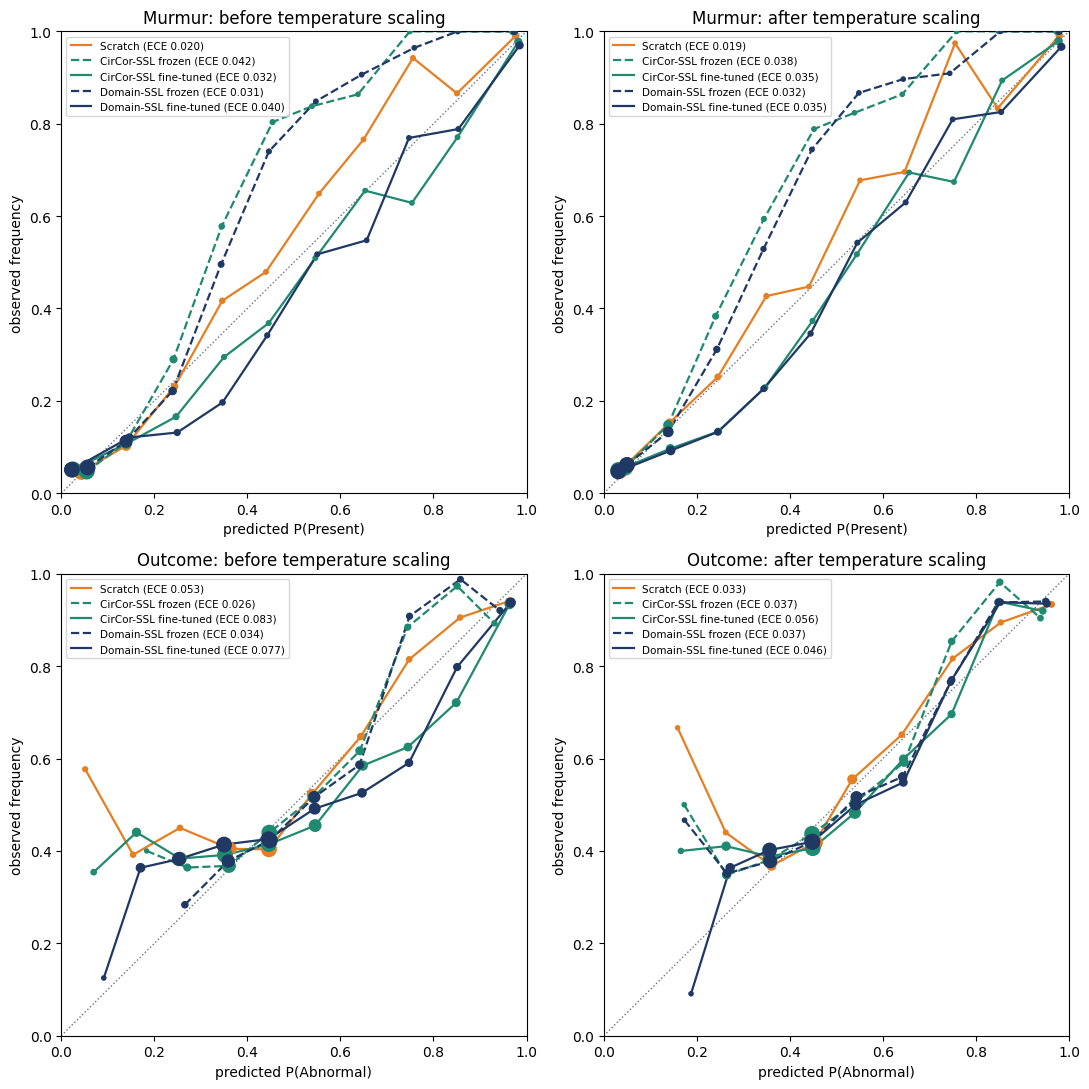

In [13]:
def reliability(y, p, n_bins=10):
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    xs, ys, ns = [], [], []
    for b in range(n_bins):
        m = bins == b
        if m.sum() >= 5:
            xs.append(p[m].mean()); ys.append(y[m].mean()); ns.append(m.sum())
    return np.array(xs), np.array(ys), np.array(ns)

fig, axes = plt.subplots(2, 2, figsize=(11, 11))
for r, task in enumerate(TASKS):
    ir = EVAL_REC[task]
    for c, m in enumerate(["single", "temp"]):
        ax = axes[r, c]
        ax.plot([0, 1], [0, 1], ":", color=GRAY, lw=1)
        for arm in ARMS:
            x, yv, n = reliability(LABEL[task][ir], OOF[(arm, task, m)][ir])
            ece = POINT[(arm, task, m, "recording", "ECE")]
            ax.plot(x, yv, ARM_LS[arm], color=ARM_COLOR[arm], lw=1.6, label=f"{ARM_NAME[arm]} (ECE {ece:.3f})")
            ax.scatter(x, yv, s=8 + 100 * n / n.max(), color=ARM_COLOR[arm], zorder=3)
        pos = "P(Present)" if task == "murmur" else "P(Abnormal)"
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel=f"predicted {pos}", ylabel="observed frequency",
               title=f"{task.capitalize()}: {'before' if m == 'single' else 'after'} temperature scaling")
        ax.legend(fontsize=7.5, loc="upper left")
plt.tight_layout(); plt.savefig(FIG_DIR / "rq2_reliability.png", dpi=200); plt.show()

## 11. Training diagnostics

*Components: ② SSL. A check that every arm trained properly and none hit the epoch cap while still improving.*

`at_cap` counts units whose best epoch fell in the last 5 of 60 epochs. Any non-zero count is flagged.

                         best_epoch_mean  best_epoch_min  best_epoch_max  at_cap  val_logloss  minutes_total
task    arm                                                                                                 
murmur  circor_finetune           11.667               3              26       0        0.186         44.237
        circor_frozen             39.556              19              57       1        0.245         10.915
        domain_finetune           14.778               2              35       0        0.195         49.753
        domain_frozen             36.222              26              47       0        0.270         11.489
        scratch                   25.556              12              39       0        0.214         62.643
outcome circor_finetune            3.889               0              14       0        0.600         35.002
        circor_frozen             11.333               0              26       0        0.607          1.118
        domain_fine

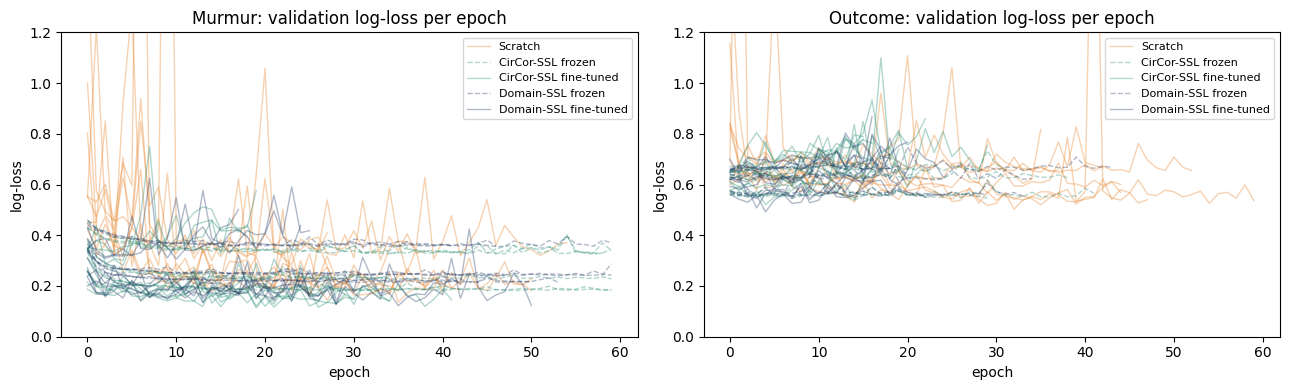

,arm,task,fold,F1 (macro),Accuracy,Weighted accuracy,AUC,Cost (c_outcome)
0,Scratch,murmur,0,0.839,0.880,0.877,0.953,NaN
1,Scratch,murmur,1,0.832,0.889,0.857,0.945,NaN
2,Scratch,murmur,2,0.854,0.901,0.850,0.899,NaN
3,Scratch,outcome,0,0.629,0.635,0.737,0.735,10414.581
4,Scratch,outcome,1,0.545,0.556,0.648,0.632,12876.285
5,Scratch,outcome,2,0.579,0.592,0.753,0.665,9978.058
6,CirCor-SSL frozen,murmur,0,0.881,0.918,0.882,0.936,NaN
7,CirCor-SSL frozen,murmur,1,0.811,0.872,0.848,0.896,NaN
8,CirCor-SSL frozen,murmur,2,0.810,0.867,0.817,0.890,NaN
9,CirCor-SSL frozen,outcome,0,0.616,0.616,0.648,0.711,12026.813


In [14]:
tlog = pd.read_csv(log_path)
tlog["at_cap"] = tlog.best_epoch >= cfg.epochs - 5
print(tlog.groupby(["task", "arm"]).agg(best_epoch_mean=("best_epoch", "mean"), best_epoch_min=("best_epoch", "min"),
                                         best_epoch_max=("best_epoch", "max"), at_cap=("at_cap", "sum"),
                                         val_logloss=("best_val_logloss", "mean"), minutes_total=("minutes", "sum")).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task in zip(axes, TASKS):
    for arm in ARMS:
        for f in range(cfg.n_folds):
            for s in cfg.seeds:
                cv = np.load(UNIT_DIR / f"{arm}_{task}_f{f}_s{s}.npz")["curve"]
                ax.plot(cv, ARM_LS[arm], color=ARM_COLOR[arm], alpha=0.35, lw=1, label=ARM_NAME[arm] if (f == 0 and s == cfg.seeds[0]) else None)
    ax.set(title=f"{task.capitalize()}: validation log-loss per epoch", xlabel="epoch", ylabel="log-loss", ylim=(0, 1.2)); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "rq2_val_curves.png", dpi=200); plt.show()

pf = []
for arm in ARMS:
    for task in TASKS:
        ip = EVAL_PAT[task]
        for f in range(cfg.n_folds):
            sel = ip[PAT.fold.values[ip] == f]
            y = PLABEL[task][sel]; p = PATP[(arm, task, "ens_temp")][sel]
            yhat = (p >= THR[(arm, task, "ens_temp", f)]).astype(int)
            pf.append({"arm": ARM_NAME[arm], "task": task, "fold": f, **{k: round(v, 3) for k, v in patient_metrics(y, p, yhat, task).items()}})
display(pd.DataFrame(pf))

## 12. Save everything later notebooks need

*Components: all five, by hand-off.*

| file | contents | used by |
|---|---|---|
| `rq2_folds.csv` | folds, groups, roles (copy of part a's) | every later RQ |
| `rq2_windows.csv` | window → recording, start time | RQ3, RQ5, RQ6 |
| `frozen_embeddings/emb_<corpus>_f<fold>.npy` | frozen BYOL-A embedding of every window | optional analyses |
| `units/*.npz`, `models/*.pt` | window logits, MC-Dropout logits, curves; trained heads / networks | RQ6 (ablation rows), re-analysis |
| `rq2_recording_predictions.csv`, `rq2_patient_predictions.csv` | out-of-fold probabilities, uncertainties, thresholds, decisions | RQ6 ablation rows |
| `rq2_temperatures.csv`, `rq2_thresholds.csv`, `rq2_training_log.csv` | fitted temperatures, validation thresholds, training log | report |
| `rq2_results.csv`, `rq2_arm_differences.csv` | the tables above | RQ2 report |
| `rq2_system_choice.json` | which encoders RQ3 starts from | RQ3 |

**Next:** RQ3 needs the RQ2a output (encoders) and this output (`rq2_system_choice.json`, folds, windows).

In [15]:
rp = []
for arm in ARMS:
    for task in TASKS:
        df = man[["wid", "patient_id", "group", "location", "fold", "murmur", "outcome"]].copy()
        df.insert(0, "task", task); df.insert(0, "arm", arm)
        df["y"] = LABEL[task]
        for m in METHODS:
            df[f"p_{m}"] = OOF[(arm, task, m)]
        for k, v in UNC[(arm, task)].items():
            df[k] = v
        rp.append(df)
pd.concat(rp).to_csv(OUT / "rq2_recording_predictions.csv", index=False)

pp = []
for arm in ARMS:
    for task in TASKS:
        for m in METHODS:
            df = PAT[["patient_id", "group", "fold", "murmur", "outcome"]].copy()
            df.insert(0, "method", m); df.insert(0, "task", task); df.insert(0, "arm", arm)
            df["y"] = PLABEL[task]
            df["p"] = PATP[(arm, task, m)]
            df["threshold"] = [THR[(arm, task, m, f)] for f in PAT.fold.values]
            df["pred"] = (df.p >= df.threshold).astype(int)
            pp.append(df)
pd.concat(pp).to_csv(OUT / "rq2_patient_predictions.csv", index=False)

temps.to_csv(OUT / "rq2_temperatures.csv", index=False)
thresholds.to_csv(OUT / "rq2_thresholds.csv", index=False)
results.drop(columns=["arm_name"]).to_csv(OUT / "rq2_results.csv", index=False)
diffs.drop(columns=["cell"]).to_csv(OUT / "rq2_arm_differences.csv", index=False)
json.dump({k: (list(v) if isinstance(v, tuple) else v) for k, v in cfg.__dict__.items()}, open(OUT / "rq2_config.json", "w"), indent=2)

total = sum(f.stat().st_size for f in OUT.rglob("*") if f.is_file()) / 1e6
print(f"saved to {OUT} ({total:.0f} MB):")
for fpath in sorted(OUT.glob("*")):
    print("  ", fpath.name, f"({len(list(fpath.glob('*')))} files)" if fpath.is_dir() else "")

saved to /kaggle/working/rq2_outputs (2662 MB):
   figures (2 files)
   frozen_embeddings (6 files)
   models (90 files)
   rq2_arm_differences.csv 
   rq2_config.json 
   rq2_folds.csv 
   rq2_patient_predictions.csv 
   rq2_recording_predictions.csv 
   rq2_results.csv 
   rq2_system_choice.json 
   rq2_temperatures.csv 
   rq2_thresholds.csv 
   rq2_training_log.csv 
   rq2_windows.csv 
   units (90 files)
